In [1]:
import numpy as np
import scipy as sp

import matplotlib.pyplot as plt
%matplotlib inline

from scipy.integrate import simps

from scipy import interpolate


1.5500139758995866 0 4.200376752756975 0.040350682708337866
1.2729578844455418


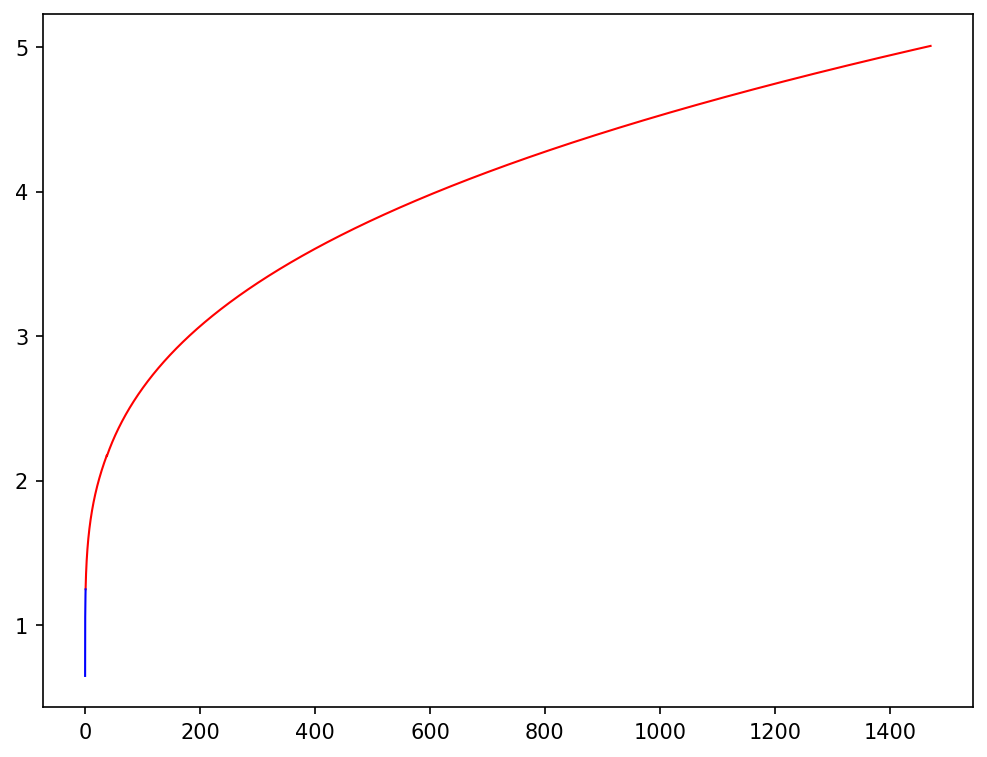

In [2]:
#!/usr/bin/env python

import math
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d


'''
http://www.nist.gov/srd/upload/jpcrd551.pdf
Page 1267
'''

a_90_1 = [1.392408,0.527153,0.166756,0.050988,0.026514,0.001975,-0.017976,0.005409,0.013259,0.0]
a_90_2 = [3.146631,1.357655,0.413923,0.091159,0.016349,0.001826,-0.004325,0.004973,0.0,0.0]
B1 = 5.6
C1 = 2.9
B2 = 10.3
C2 = 1.9

def T90(pressure):
	#Input pressure is in Torr
	pressure = pressure*133.322 #Convert to Pa from Torr
	temp = 0
	if(pressure >= 0.8626*133.322 and pressure <= 37.82*133.322):
		for x,y in enumerate(a_90_1):
			temp =  temp + y*math.pow((math.log(pressure)-B1)/C1,x)
	elif(pressure > 37.82*133.322 and pressure <= 1471*133.322):
		for x,y in enumerate(a_90_2):
			temp =  temp + y*math.pow((math.log(pressure)-B2)/C2,x)
	else:
		temp = 0
	return temp

def P90(temp):
	log_p = 12.2440 - 59.83/(8.314510*float(temp)) + (5.0/2.0)*math.log(float(temp))
	pressure = math.exp(log_p) 
	pressure = pressure/10.0 #Not sure why there is a divide by 10 here...
	pressure = pressure/133.322 #Convert Pa to Torr
	return pressure
	
print(T90(597.1/133.322),T90(1.475/133.322),T90(99230/133.322),P90(0.900))

temp = []
pressure = []
for i in range(8626,14710000,100):
	pressure.append(i/10000.0)
	temp.append(T90(i/10000.0))

temp2 = []
pressure2 = []
for i in range(650,1250,1):
	temp2.append(i/1000.0)
	pressure2.append(P90(i/1000.0))

temp_interp = interp1d(pressure,temp,kind='linear',bounds_error=False,fill_value = 0)
print(temp_interp(0.999))



plt.plot(pressure,temp, 'r')
plt.plot(pressure2, temp2, 'b')

plt.show()

In [3]:

'''
He4 Vapor Pressure to temperature: Emperical formula
http://journals.aps.org/pr/pdf/10.1103/PhysRev.100.743
'''

def He4Pressure(temp):
    '''
    Return He4 Vapor pressure at temp in torr
    '''
    
    I = 4.6202
    A = 6.399
    B = 2.541
    C = 0.00612
    D = 0.5197
    alpha = 7.00
    beta  = 14.14
    
    log_p = I - (A/temp)+B*np.log(temp)+(C/2.0)*temp**2 
    log_p = log_p - D*((alpha*beta)/(np.power(beta,2)+1) - temp**-1)*np.arctan(alpha*temp-beta) 
    log_p = log_p - (alpha*D)/(2*(beta**2+1))*np.log((temp**2)/(1+(alpha*temp-beta)*(alpha*temp-beta)))
    return np.exp(log_p)



T0 = np.arange(2.0, 5., 0.01)
P0 = He4Pressure(T0)
He4Temp = interpolate.interp1d(P0, T0)

In [4]:
He4Pressure(3.80)/He4Pressure(4.20)

0.6670003033075389

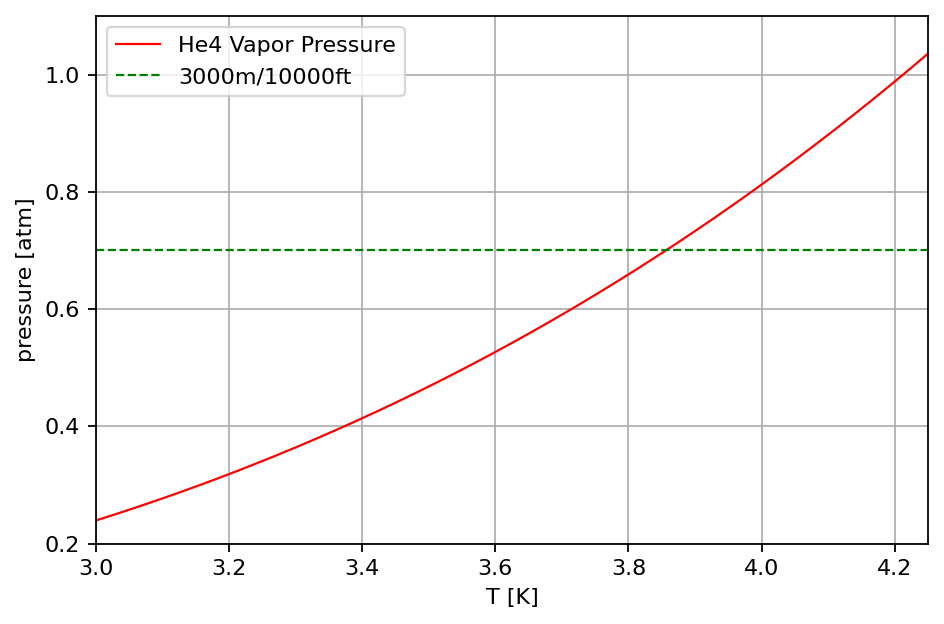

In [6]:

T = np.arange(1.0, 5., 0.01)
P = He4Pressure(T)

atm = 760
dp  = 40

fig,ax=plt.subplots(figsize=(6,4), dpi=160)


plt.plot(T, P/atm, 'r', label = "He4 Vapor Pressure")
# plt.axhline(y=1, ls='--', label='1 atm')
plt.axhline(y=0.7, c='g', ls='--', label='3000m/10000ft')

# plt.yscale('log')

plt.xlabel('T [K]')
plt.ylabel('pressure [atm]')

plt.legend(fontsize=10)

plt.xlim([3, 4.25])
plt.ylim([0.2,1.1])

plt.grid()
plt.tight_layout()

plt.savefig('he4_VaporPressure.png', dpi=120)

In [8]:
he4 = np.loadtxt('../he4_v' )
he3 = np.loadtxt('../he3_v' )


He3 = np.stack((np.sort(he3[0::2]), np.sort(he3[1::2]))) 
He4 = np.stack((np.sort(he4[0::2]), np.sort(he4[1::2]))) 

In [3]:
np.savetxt('He3_vapor_pressure.txt',He3.T, fmt='%.6e', header='He3 vapor pressure\nT[K] P[mbar]')
np.savetxt('He4_vapor_pressure.txt',He4.T, fmt='%.6e', header='He4 vapor pressure\nT[K] P[mbar]')

(0.2, 1.5)

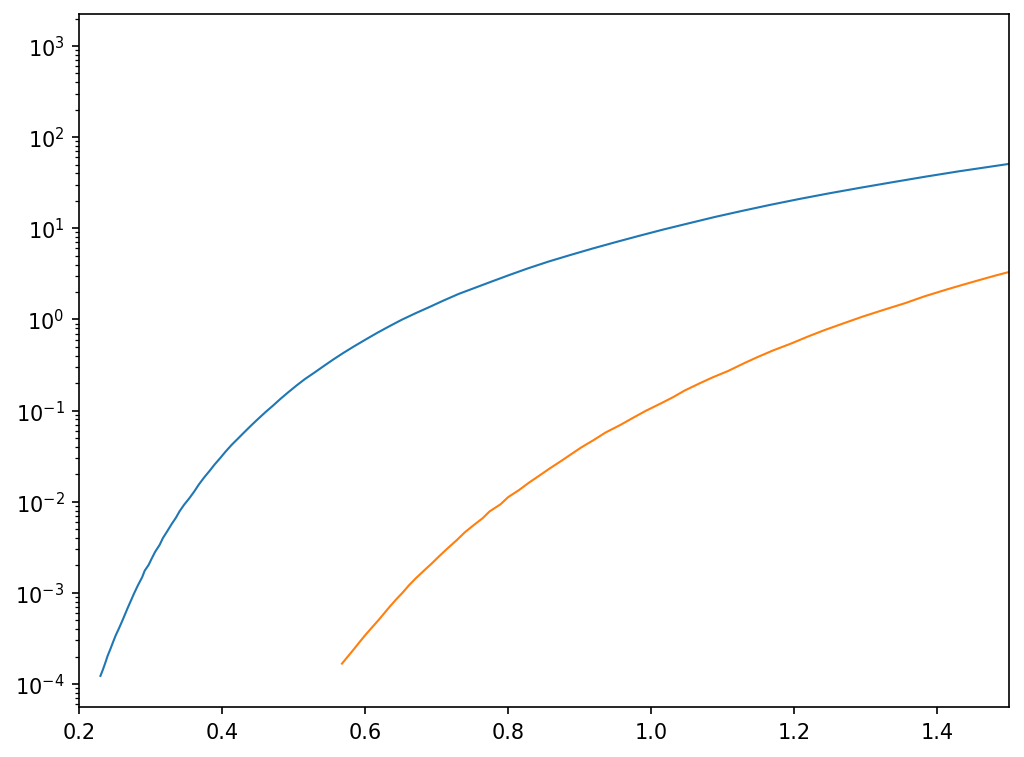

In [12]:
plt.plot(He3[0],He3[1])
plt.plot(He4[0],He4[1])

# plt.grid()
plt.yscale('log')
# plt.xscale('log')

plt.xlim([0.2,1.5])
# plt.ylim([1e-4,2e1])

## Helium 4 vapor as a function of temperature

(3.0, 4.5)

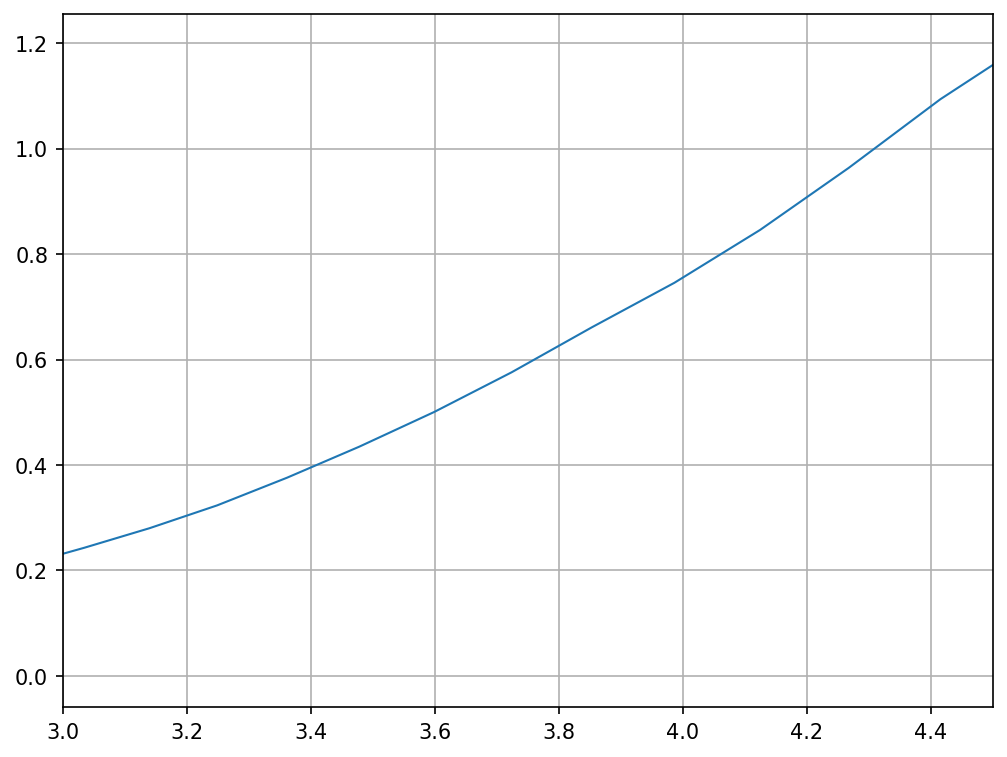

In [13]:

plt.plot(He4[0],He4[1]/760)

plt.grid()
# plt.yscale('log')

plt.xlim([3,4.5])
# plt.ylim([3,4.5])

## Helium 4 residual as a function of temperature

In [37]:
residual = np.loadtxt('He4_residual.csv', delimiter=',').T

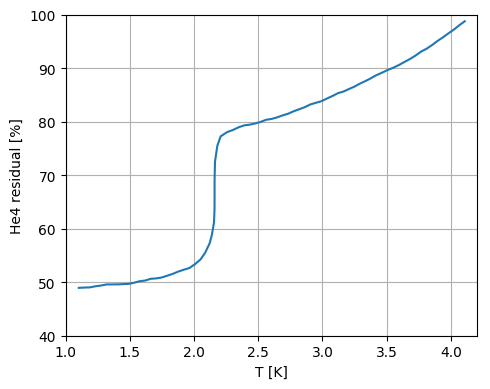

In [103]:
fig,ax=plt.subplots(figsize=(5,4), dpi=100)

plt.plot(residual[0], residual[1])

# plt.yscale('log')

plt.xlim([1,4.2])
plt.ylim([40,100])

plt.grid()

plt.ylabel('He4 residual [%]')
plt.xlabel('T [K]')

plt.tight_layout()

plt.savefig('He4_residual_remake.png')